# E70: Does removing the old count hurt the reusing task more than the new one?

**The answer.** No: by the filed rule, one direction cannot serve as ground truth here, because the new task loses more than the reusing task at block 6, and any reversal decides. At blocks 3 to 5 the reusing task loses far more. But the direction removed holds about half the residual's variance, and the random directions that set the band hold under one percent. That direction could hurt for reasons unrelated to the count, so neither the pretrained model's loss nor the gap between the tasks can yet be read as the count's causal role.

**How we got here.** The first reading removed the regression probe's one direction, which did nothing, and six softmax directions, which did something. The amendment removes the direction where the count moves the residual, and it also explains why the first direction did nothing. Ask 15, whether to try it, was taken by default after two hours without an answer, so the user did not choose it.


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens existing ones. `decisions.md` defines that without any decomposition, after Jain, Kirk, Lubana et al. 2024. A model possesses a capability if a linear readout trained on pretraining data recovers it. A fine-tune reuses it if the new map is some function of that reading. And reuse needs a causal claim: taking the readout's direction away must break the fine-tuned behaviour. That last clause had never been read on a pair whose answer is known by construction.

**The model.** LOW is a small transformer of 6 blocks and width 192, pretrained to count the letter a when asked `C a 40`.

**The pair.** Every state is LOW fine-tuned on `C b 40` rows of natural text.

- **Task P** answers the count of a plus one. It reuses the old count, by construction.
- **Task N** answers the count of b. It needs a new count, by construction.

Both tasks ran at two learning rates and five seeds, saved at 1,000 and 10,000 steps, the same grid as an earlier stage. Those states were lost with an old clone, so LOW and all 20 runs were retrained from the same code and seeds. The filed rule reads the 20 states at 10,000 steps.

**Two probes on LOW,** each trained per block on `C a 40` rows, read at the `=` position, with no possession threshold.

- **The ridge probe** regresses the count on the residual and gives one direction, its unit weight vector. This is the task as asked, and the filed headline.
- **The softmax probe** predicts the count as a class. The classes it sees are the counts 10 to 16, so its centred columns span six directions out of 192. It is reported beside the ridge probe, to ask whether one direction misses a count held in several.

**The removal.** With $h$ the residual after block $b$ at `=` and $U$ an orthonormal basis of the probe's directions, $h$ becomes $h - U U^\top h$ at that one position. Later blocks still read the text.

**The score.** Let $D_{\text{state}}$ be the state's mean drop in the log-odds of its own answer under the removal, $D_{\text{LOW}}$ be LOW's drop for the same answer on the same rows, and $G$ be the state's mean log-odds gain over LOW. The share of the gain lost is $(D_{\text{state}} - D_{\text{LOW}}) / G$. A share of 0 means the state lost no more than LOW did, and 1 means the whole gain went. The raw share is $D_{\text{state}} / G$.

**The controls,** each read in the same job, and what each rules out:

- LOW's count accuracy against the old run, to rule out a different model under the same name.
- LOW's own log-odds drop under the removal, on `C a 40` rows, to rule out a removal that does nothing. If it costs LOW nothing, a null on the tasks means nothing.
- 20 random directions per block, or 20 random six-direction subspaces, on LOW and on every state. The 95th percentile of their size sets the band at each block, so any removal of that size has to beat it.

**The rule.** At a block, the smallest P share minus the largest N share must exceed that block's band. All ten states of a side must clear all ten of the other.


**The amendment.** The first reading, below, left one direction that reads the count perfectly and does nothing when removed. Ask 15, whether to try a direction chosen another way, was taken by default at 15:28 on 2026-11-03. Two directions are compared from here on.

- **The covariance direction** is the unit covariance of the residual with the count of a, per block, on the rows the ridge probe was fit on. It is where the count moves the residual.
- **The regression direction** is the ridge probe's unit weights, the direction the first reading removed.

The removal, the rows, the random draws and the score are the first reading's, and nothing is retrained. LOW is read first, and the tasks only if LOW loses log-odds. Three things are new, each to rule something out:

- **Accuracy after removal,** because a large log-odds drop can leave the answer in place.
- **A ridge refit on fresh rows after each removal,** to ask whether the count can still be read at all. It rules out a removal that does not do what it claims.
- **The share of the residual's variance along each direction,** to test why the two directions differ.

**The filed tree.** A block is read only if LOW loses log-odds there above the band. Then the first match wins: a reversal at any read block gives "cannot serve"; otherwise the rule holding at a read block from 1 to 5 gives "separates". So a single reversal decides, whatever else holds.


## What we expected, and why

We expected the removal to work on LOW, at least at the last block, since a readout that reads the count should be using what the model uses.

We expected the rule to hold. P's answer is a function of the old count, so removing the count should cost P a lot: over half its gain at block 6. N's answer does not depend on the count of a, so N should sit near the band at blocks 1 to 5, and might rise at block 6, where every answer shares the output head.

We expected the function test to split the pair cleanly. A table from LOW's reading to the state's answer should score near the probe's accuracy on P and near its floor on N.

The plan named one blind spot in advance: the count of a and the count of b are correlated on these rows, so a direction shared between them would cost N as well.


**For the amendment,** we expected less damage than we saw. LOW would lose about 0.3 to 5 log-odds at some of blocks 3 to 6, with low confidence, and keep accuracy at or above about 0.7, because the softmax head can still separate classes in other directions. The refit would read the count near the 0.3575 floor after the covariance direction, which is close to algebra, and above 0.9 after the regression direction from block 3.

Task P would lose more than the band and less than under the six softmax directions at most blocks, most at blocks 4 and 5. Task N would stay under P at blocks 4 and 5 and above the band at blocks 4 to 6, up to about its six-direction values of 0.20, 0.34 and 0.49. The weak lean was that the rule would hold at block 4 or 5 and not at block 6. "Cannot serve" was named as a live outcome because the two counts correlate.


In [1]:
import json
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/pcfg_anchors")
RES = json.loads((ROOT / "results" / "e70.json").read_text())
FIG = ROOT / "figures"


def show(name):
    display(Image(filename=str(FIG / name), width=760))


def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


p, c = RES["probes"], RES["control"]
print(f"LOW count of a {RES['low']['count_a']:.5f}, old run {RES['low']['count_a_a1']:.5f}")
print(f"correlation of count(a) and count(b) on 'C b 40' rows {p['corr_count_a_count_b_on_C_b_40']:.2f}")
ten_k = [f for f in RES["finetunes"].values() if f["step"] == 10000]
print(f"10K states: lowest task accuracy {min(f['task_acc'] for f in ten_k):.4f}, "
      f"largest gap to the earlier stage {max(abs(f['task_acc'] - f['task_acc_c1b']) for f in ten_k):.4f}")
table(["block", "ridge accuracy", "softmax accuracy", "softmax, shuffled labels", "softmax, earlier run"],
      [[i + 1, f"{p['ridge']['acc_a'][i]:.3f}", f"{p['softmax']['acc_a'][i]:.3f}", f"{p['softmax']['shuffled_a'][i]:.3f}",
        f"{p['softmax']['acc_a_a1c'][i]:.3f}"] for i in range(6)])


LOW count of a 0.99975, old run 0.99975
correlation of count(a) and count(b) on 'C b 40' rows -0.50
10K states: lowest task accuracy 1.0000, largest gap to the earlier stage 0.0005


| block | ridge accuracy | softmax accuracy | softmax, shuffled labels | softmax, earlier run |
|---|---|---|---|---|
| 1 | 0.380 | 0.356 | 0.331 | 0.342 |
| 2 | 0.998 | 0.919 | 0.331 | 0.871 |
| 3 | 1.000 | 0.972 | 0.335 | 0.916 |
| 4 | 1.000 | 0.995 | 0.339 | 0.985 |
| 5 | 1.000 | 0.998 | 0.354 | 0.999 |
| 6 | 1.000 | 1.000 | 0.356 | 1.000 |

## What we observed

The first four questions are the first reading, on the two probes. The three after them are the amendment, and they are what the answer above rests on.


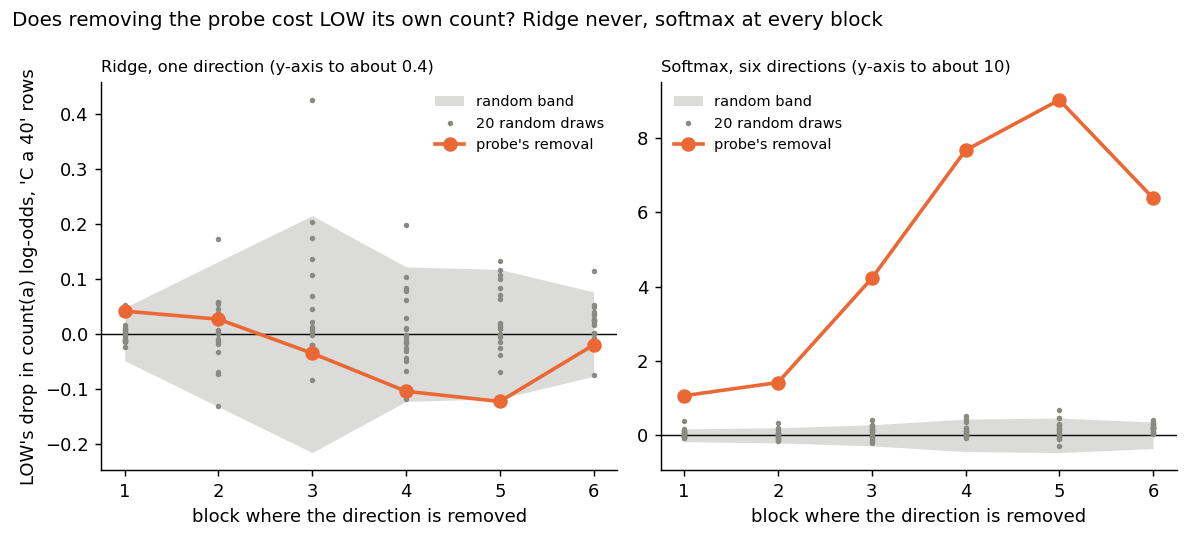

In [2]:
show("e70_low.png")


### Does removing the probe cost LOW its own count?

**Reading it.** The ridge direction does not, at any block, and the softmax directions do, at every block. The figure's left panel plots LOW's log-odds drop against 20 random single directions. The ridge removal stays inside or under the grey band everywhere, and at blocks 4 and 5 it nudges the log-odds up, not down. Single random directions moved LOW by more than the probe's direction did. The right panel, on a scale about twenty times larger, has the softmax removal above its band at all six blocks, at most 9 log-odds against a band of about 0.5.

So one direction that reads the count perfectly can be taken away with no effect on the model that holds the count. Why stayed open until the amendment, below. Whatever follows on the ridge probe has no working control under it.


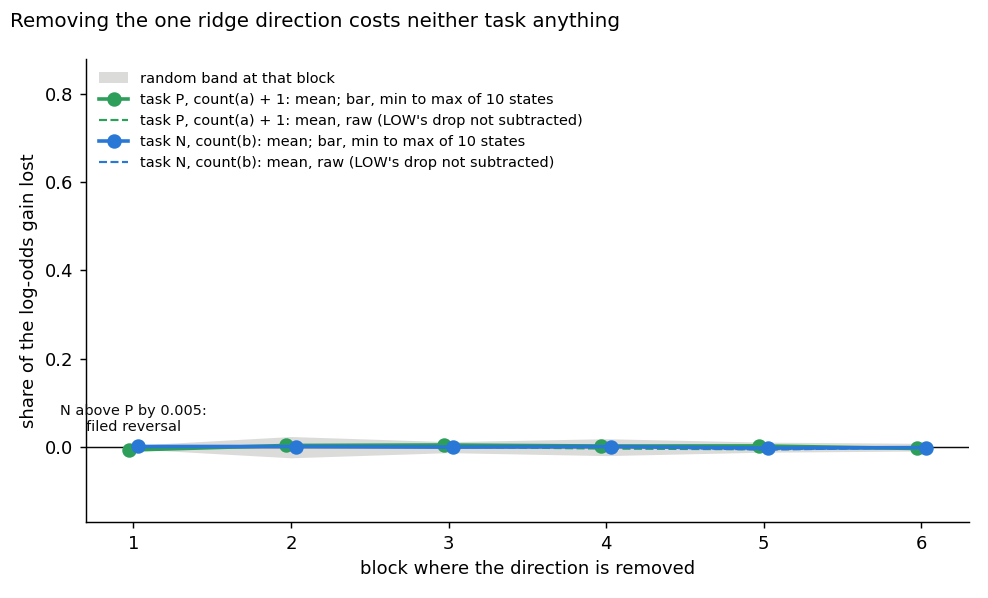

In [3]:
show("e70_ridge.png")


### Does removing the one ridge direction cost task P more than task N?

**Reading it.** No: it costs neither task anything. The filed verdict is "does not separate", and this misses our lean that the rule would hold. Every share at every block lies within 0.01 of zero, on the same axes as the next figure. This cannot be read as a negative about the definition, because the removal does nothing on LOW either. The filed rule also returned a reversal at block 1, with N above P by 0.005 against a band of 0.004. That is half a percent of the gain, at the block where this probe reads barely above its floor, on a removal with no effect on LOW.


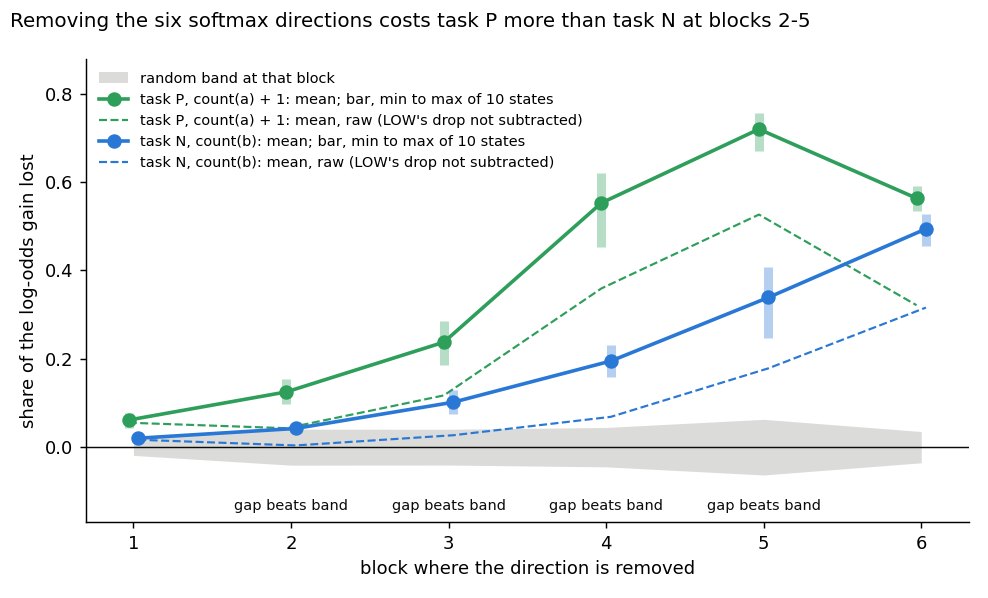

In [4]:
show("e70_softmax.png")


### Does removing the six softmax directions cost task P more than task N?

**Reading it.** Yes at blocks 2 to 5, by the filed rule, but it is a difference of degree and not the clean split we predicted. In the figure the whole P range clears the whole N range by more than the band at those four blocks, most widely at block 5, where P loses 0.72 of its gain and N loses 0.34. At blocks 1 and 6 the rule does not hold. P passes the half-gain mark at block 6, as leaned, with 0.56. N misses its prediction of staying near the band up to block 5. It reads 0.20 at block 4 and 0.34 at block 5, against bands of 0.045 and 0.063.

This removes six directions, not the one the task named, so it does not by itself answer the task as asked.

**What subtracting LOW's drop does.** The scored share subtracts LOW's drop, and LOW's drop on these rows is negative. Removing its count directions raises LOW's log-odds of P's answer by about 5 at blocks 4 and 5, and of N's answer by about 3. Subtracting a negative number adds to the share, as the gap between the solid and dashed lines shows: about 0.19 for P, and 0.13 to 0.16 for N. In the raw share the gap between the tasks survives at blocks 4 and 5: the smallest P is 0.28 and 0.50, and the largest N is 0.08 and 0.22. At blocks 2 and 3 the raw gap is 0.01 and 0.04, under the scored band, so those two blocks lean on the subtraction. At block 6 the raw shares are equal, at 0.32.

**A candidate for N's rise, not a cause.** The count of a and the count of b correlate at -0.50 on these rows, the blind spot the plan named. A direction shared by the two counts would cost N as well. This run did not test that.

**At 1,000 steps** the shares run higher than at 10,000 on both tasks, by up to about 0.14 on N and 0.12 on P. Five of the ten N states there have not yet learned the task, at about 0.49 accuracy, so the filed rule leaves 1K out. The gain is also smaller there, about 21 log-odds on P and 11 on N against 26 and 22, while LOW's subtracted term stays fixed.


In [5]:
rows = RES["r2"]["softmax"]["rows"]
mean = lambda r, name, key="shares": np.mean(list(r[key][name].values()))
table(["block", "P share, raw", "N share, raw", "band", "rule"],
      [[r["block"], f"{mean(r, 'P_10000'):.2f}, {mean(r, 'P_10000', 'shares_raw'):.2f}",
        f"{mean(r, 'N_10000'):.2f}, {mean(r, 'N_10000', 'shares_raw'):.2f}", f"{r['band']:.3f}", r["call"]] for r in rows])
gf = RES["gf_by_block"]
floor = {t: next(RES["states"][s]["gf"][0]["floor"] for s in gf[f"{t}_10000"]) for t in "PN"}
table(["block", "table on P", "floor on P", "table on N", "floor on N"],
      [[i + 1, f"{np.mean([v[i] for v in gf['P_10000'].values()]):.3f}", f"{floor['P']:.3f}",
        f"{np.mean([v[i] for v in gf['N_10000'].values()]):.3f}", f"{floor['N']:.3f}"] for i in range(6)])


| block | P share, raw | N share, raw | band | rule |
|---|---|---|---|---|
| 1 | 0.06, 0.06 | 0.02, 0.02 | 0.019 | neither |
| 2 | 0.13, 0.04 | 0.04, 0.00 | 0.041 | holds |
| 3 | 0.24, 0.12 | 0.10, 0.03 | 0.041 | holds |
| 4 | 0.55, 0.36 | 0.20, 0.07 | 0.045 | holds |
| 5 | 0.72, 0.53 | 0.34, 0.18 | 0.063 | holds |
| 6 | 0.56, 0.32 | 0.49, 0.32 | 0.035 | neither |

| block | table on P | floor on P | table on N | floor on N |
|---|---|---|---|---|
| 1 | 0.367 | 0.353 | 0.343 | 0.357 |
| 2 | 0.997 | 0.353 | 0.386 | 0.357 |
| 3 | 1.000 | 0.353 | 0.387 | 0.357 |
| 4 | 1.000 | 0.353 | 0.387 | 0.357 |
| 5 | 1.000 | 0.353 | 0.387 | 0.357 |
| 6 | 1.000 | 0.353 | 0.387 | 0.357 |

### Is each task's answer a function of LOW's reading?

**Reading it.** Yes for P, no for N, as predicted, on all ten states of each side at 10K. The second table is a lookup from LOW's rounded ridge reading to the state's answer, fitted on half the rows and scored on the other half. On P it follows the probe's accuracy and reaches 1 from block 3. On N it stays at 0.39 from block 2, against a floor of 0.36. The reading comes from the ridge probe, so this direction reads the count well enough to give P's answer exactly, while removing it does nothing. This test reads answers alone, and the answers are fixed by each task's construction, so it checks the pair more than it checks the removal.


### Why did the regression direction do nothing?

**Reading it.** Because the count is still readable without it. After removing the regression direction, a fresh ridge refit reads the count at 1.0 from block 3 and at 0.993 at block 2, against 0.9975 with nothing removed. After removing the covariance direction, the same refit reads 0.3575 to 0.3705, against a floor of 0.3575. The number moved, so this answers the first reading's puzzle. The regression direction holds 0.00006 to 0.03 of the residual's variance, the covariance direction 0.30 to 0.78, and the cosine between them is at most 0.32.

The fall to the floor is close to algebra, since zero covariance leaves a linear reader of the count nothing, so it checks the removal and is not a discovery. Variance alone does not explain the regression direction's silence either. At blocks 4 to 6 it holds three to seven times what a random direction holds, and it still costs LOW nothing.


In [6]:
A1 = json.loads((ROOT / "results" / "e70_a1.json").read_text())
w, l = A1["why"], A1["control"]["pattern"]
table(["block", "refit, nothing removed", "after regression", "after covariance", "variance, regression", "variance, covariance", "variance, random"],
      [[i + 1, f"{w['before'][i]:.4f}", f"{w['refit_after_ridge'][i]:.4f}", f"{w['refit_after_pattern'][i]:.4f}",
        f"{w['var_share_ridge'][i]:.5f}", f"{w['var_share_pattern'][i]:.3f}", f"{w['var_share_random'][i]:.4f}"] for i in range(6)])


| block | refit, nothing removed | after regression | after covariance | variance, regression | variance, covariance | variance, random |
|---|---|---|---|---|---|---|
| 1 | 0.3800 | 0.3735 | 0.3575 | 0.00006 | 0.776 | 0.0045 |
| 2 | 0.9975 | 0.9930 | 0.3590 | 0.00172 | 0.505 | 0.0039 |
| 3 | 1.0000 | 1.0000 | 0.3690 | 0.00353 | 0.560 | 0.0067 |
| 4 | 1.0000 | 1.0000 | 0.3655 | 0.01596 | 0.561 | 0.0043 |
| 5 | 1.0000 | 1.0000 | 0.3705 | 0.03162 | 0.530 | 0.0045 |
| 6 | 1.0000 | 1.0000 | 0.3620 | 0.02545 | 0.297 | 0.0050 |

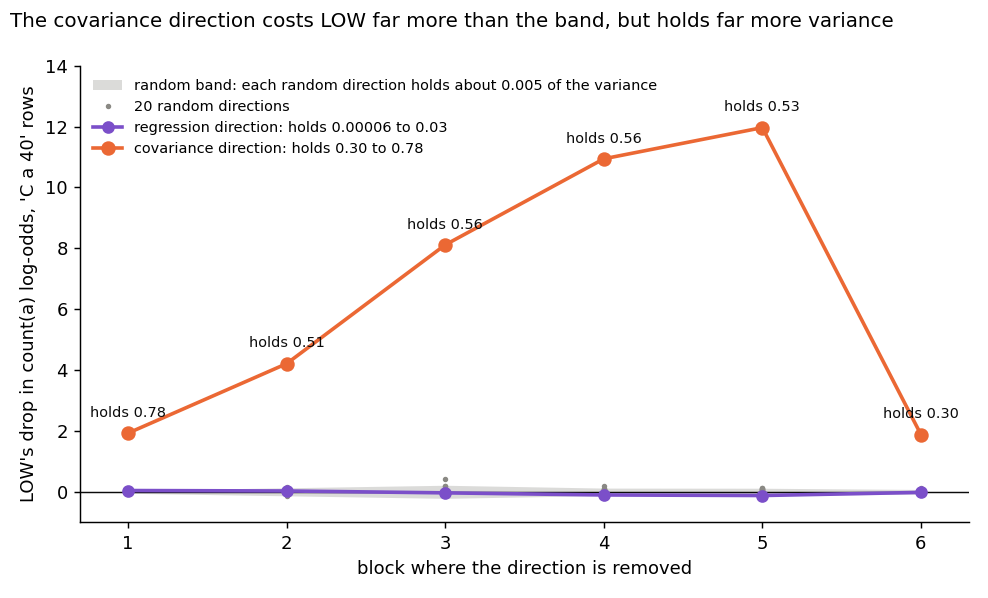

In [7]:
show("e70_a1_low.png")


### Does removing the covariance direction cost LOW its count?

**Reading it.** Yes by the filed test, at all six blocks, and by much more than we filed. The figure plots LOW's log-odds drop per block. The covariance direction drops it 1.9 to 12, against bands of at most 0.22, while the regression direction stays on the zero line with the random draws. LOW's accuracy on its own count falls from 1.0 to 0.36 at block 5, which is the floor of always answering the commonest count. At blocks 1 to 5 this one direction costs LOW more log-odds than the six softmax directions did. The next section limits what this can be read as.


### Can that loss be read as the count's causal role?

**Reading it.** Not yet, and this limits the result as much as the verdict does. The band comes from random single directions, which hold about 0.004 to 0.007 of the residual's variance. The covariance direction holds 0.30 to 0.78, which is 60 to 170 times as much. So the band shows that a small random direction does little. It says nothing about what a direction this large would do if it had no tie to the count.

Removing half of a residual's variance could hurt for reasons unrelated to the count. The bands on the tasks come from the same random directions, so the same limit applies there. So "LOW loses log-odds above the band" and the gap between the tasks at blocks 3 to 5 cannot yet be read as the count's causal role.

Neither the plan nor the filed list of what the measurement is blind to named this. The plan filed the variance share as a reading, used only to test why the two directions differ, and the limit was found on reading the result. It does not touch the filed verdict, which stands.

The control this calls for was asked of the user and is neither decided nor run: remove a direction of matching variance with no covariance with the count. It has its own limit. A direction with no covariance with the count is at right angles to the covariance direction, so it holds at most what that direction leaves: 0.22, 0.49, 0.44, 0.44, 0.47 and 0.70 at blocks 1 to 6. An exact match is therefore impossible at blocks 1 to 5, and only the largest such direction can be removed there.


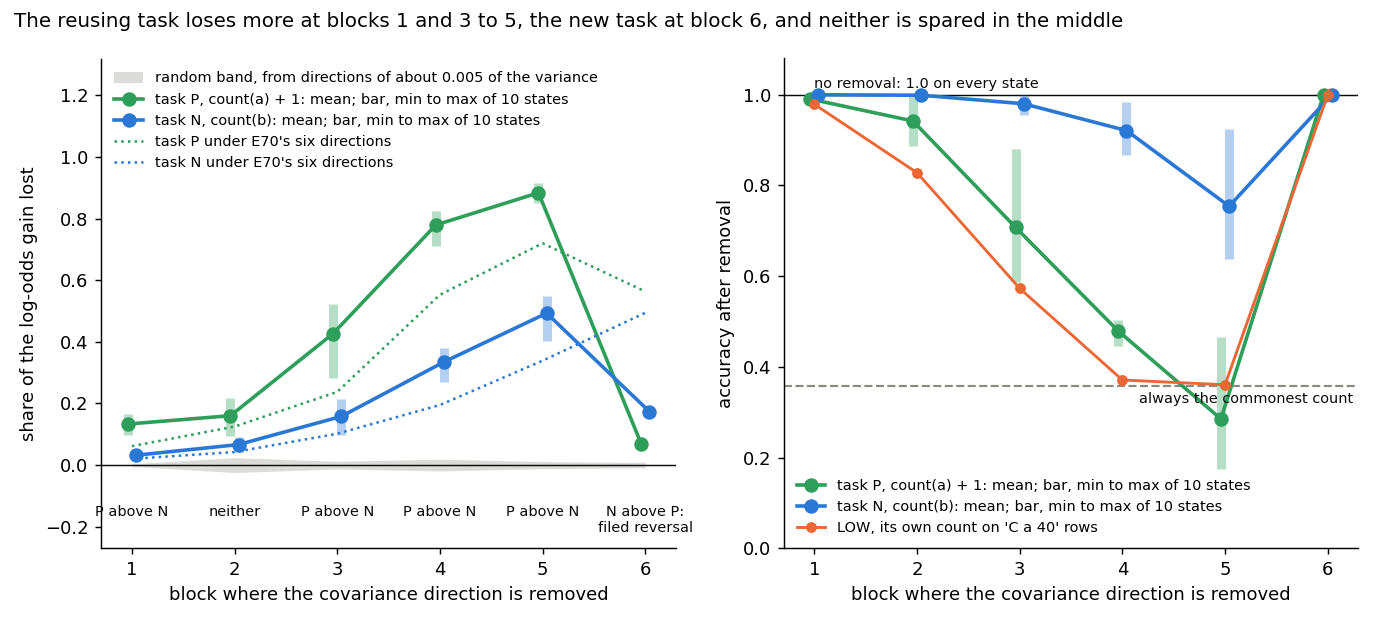

In [8]:
show("e70_a1_tasks.png")


### Does removing the covariance direction cost task P more than task N?

**Reading it.** The filed verdict is "cannot serve", because of a reversal: at block 6, task N loses more than task P, by 0.081 against a band of 0.009. LOW has teeth at all six blocks, so all six are read, and the tree's first-match rule makes any reversal decide. The verdict stands. Blocks 1 and 3 to 5 go the other way by the filed gap rule, and block 2 is neither. The rule read over all blocks printed "separates" beside the branch, and the tree is what decides.

At blocks 3 to 5, P loses 0.427, 0.779 and 0.884 of its gain and N loses 0.158, 0.335 and 0.493. Answers say the same. P's accuracy falls to 0.707, 0.479 and 0.285, the last below the 0.35 of always answering the commonest count. N is not spared: it falls to 0.980, 0.921 and 0.754. The two counts correlate at -0.50 on these rows, so this direction could carry the count of b too. That is a candidate for N's loss that this run did not test, not its cause.

**What was read at block 6.** N's share is 0.174 and P's is 0.070. In nats, the mean share of the gain is under 0.0001 on both tasks, with 0.00016 the largest on any state, and accuracy is 1.0 on every state. The raw share, which does not subtract LOW's drop and has no band, reads P 0.071 and N 0.045. LOW's drop for N's answer there is -2.73, and for P's answer 0.04. These are what was read. The filed rule reads the scored share, so they leave the branch as it is.


In [9]:
table(["block", "P share", "N share", "band", "rule", "P accuracy", "N accuracy"],
      [[r["block"], f"{s['P_A_lo'][0]:.3f}", f"{s['N_A_lo'][0]:.3f}", f"{r['band']:.4f}", r["call"], f"{s['P_acc'][0]:.3f}", f"{s['N_acc'][0]:.3f}"]
       for r, s in zip(A1["r2"]["rows"], A1["summary"], strict=True)])
print("branch:", A1["branch"]["branch"])


| block | P share | N share | band | rule | P accuracy | N accuracy |
|---|---|---|---|---|---|---|
| 1 | 0.133 | 0.032 | 0.0042 | holds | 0.991 | 1.000 |
| 2 | 0.160 | 0.067 | 0.0241 | neither | 0.942 | 0.999 |
| 3 | 0.427 | 0.158 | 0.0125 | holds | 0.707 | 0.980 |
| 4 | 0.779 | 0.335 | 0.0191 | holds | 0.479 | 0.921 |
| 5 | 0.884 | 0.493 | 0.0114 | holds | 0.285 | 0.754 |
| 6 | 0.070 | 0.174 | 0.0087 | reversal | 1.000 | 1.000 |

branch: cannot serve


## What we learned

The definition's possession and function clauses behave as they should on a pair with known labels. Its causal clause, read as removing one direction, now has a filed answer: one direction cannot serve as ground truth here, because of the reversal at block 6.

The gap at blocks 3 to 5 is large and shows up in answers as well as log-odds, but a direction holding half the variance has no matched control, so it is a lead and not a reading of the count's causal role. The first reading's puzzle is settled in one respect: removing the regression direction leaves the count readable, which is why it could do nothing.

The six-direction result stays provisional, and it has the same open question, since its variance was not read. So for `GOALS.md`'s question of new against existing, this pair does not yet give a ground truth for scoring cheap methods on Qwen.

## How compelling is the evidence

The apparatus checks are strong for what they cover: 20 states, ten per side, five seeds and two learning rates, with the random drops reproducing the first reading's exactly. The causal reading is weak, for the first reason below.

- **The band is not matched on size.** Random directions hold about 0.004 to 0.007 of the variance and the covariance direction holds 0.30 to 0.78. Neither "LOW has teeth" nor the gap between the tasks can be read as the count's causal role until a direction of comparable size with no covariance with the count has been removed. The plan and the filed list did not name this.
- **Zero covariance covers the scalar count only.** LOW's head is a softmax over count tokens, and erasing a one-hot count can take up to six directions. So after this removal a linear reader of the scalar count fails, while a reader of each count class need not. LOW's accuracy at block 6 stayed 0.9995 with the scalar reading erased, and no later block remains there to read the text again. So "the refit reads the floor" does not mean the count is gone, and a task's loss here is the loss of this direction, not of the count as such. No reader of the count classes was fit after removal.
- **Blind spots kept from the first reading.** The removal misses a count held non-linearly and anything later blocks re-read from the text. It also cannot tell a direction used by both counts from a mechanism N shares.
- **Log-odds are not answers.** These states are very sure of their answers, with a mean probability above 0.999 on every 10K state, so a large log-odds drop can leave the answer in place. Under the six softmax directions the share of the gain in nats, recorded but not scored, reads 0.16 and 0.31 for P at blocks 4 and 5 against 0.002 and 0.013 for N, and about 0.001 on both at block 6. The median row on P at block 5 loses 0.01 to 0.02 nats at rate 1e-4 and 0.33 to 0.49 at rate 1e-5. Accuracy after removal was recorded only in the amendment, where answers do change at blocks 3 to 5 and do not at block 6.
- **Check.** No independent check was run, and none is claimed. This is one retrain of LOW, with one probe seed, and the refit reads `C a 40` rows only.

## Surprises

**A filed reversal decides the amendment.** At block 6, task N loses more of its gain than task P, 0.174 against 0.070, by more than the band. No filed number predicted N above P there. The filed lean, that the rule would hold at block 4 or 5 and not at block 6, is met to the letter, and the reversal goes beyond it. We read no cause for it, and the branch stands.

**The covariance direction does much more damage than filed.** This run measured no cause for any of the misses below.

- LOW's drop reads 1.9 to 12, against a filed 0.3 to 5 at some of blocks 3 to 6. It is above the band at all six blocks and above 5 at blocks 3 to 5.
- LOW's accuracy falls to 0.573, 0.371 and 0.3605 at blocks 3 to 5, against a filed at or above about 0.7.
- P's share is over the filed ceiling of the six-direction means at blocks 2 to 5: 0.160, 0.427, 0.779 and 0.884 against 0.125, 0.238, 0.553 and 0.720. So one direction cost P more than six did at those blocks. Block 6 reads 0.070 against 0.564.
- N's share is over its filed values at blocks 4 and 5: 0.335 and 0.493 against about 0.20 and 0.34. Block 6 reads 0.174, within its filed 0.49.
- The share in nats is over its filed values at blocks 4 and 5 on both tasks: P 0.650 and 0.833 against 0.155 and 0.308, N 0.021 and 0.071 against 0.002 and 0.013.
- Task accuracy falls below the filed 0.9 on the rate 1e-4 states. P reads 0.78 to 0.88 at block 3, about 0.50 at block 4 and 0.31 to 0.47 at block 5, and N reads 0.82 to 0.93 at block 5. The rate 1e-5 states, filed as possibly under 0.9 on P at blocks 4 and 5, also fall under it on P at blocks 2 and 3 and on N at block 5.
- The variance along the regression direction reads 0.016 at block 4, against a filed under 1/192, about 0.005.

**What the amendment read as filed.** The refits, the cosine, the random controls and P's and N's order at blocks 4 and 5 all read as filed, as the scorecard shows.

**In the first reading: a filed reversal, and a filed miss, on the headline.** We predicted the one-direction rule would hold, and instead it does not separate, with N above P at block 1 by half a percent. The size is tiny and the removal has no effect on LOW, so we read no mechanism into it.

**In the first reading: the direction that reads the count does nothing when removed.** A regression direction reads the count at accuracy 1 from block 3 and supports a perfect lookup for P, yet taking it away leaves LOW's log-odds inside the random band. The amendment answers this: the count stays readable without that direction.

**In the first reading: N loses much more than predicted under the six directions.** N reads 0.34 at block 5, against a predicted value near 0.06.

Narrow: the softmax probe read up to 0.06 above its earlier run at blocks 2 and 3, and neither probe read consistently lower on `C b 40` rows at early blocks, as we had predicted.

## What next

- **Remove the largest direction with no covariance with the count,** on LOW first, then on the two tasks, about 15 minutes at $0. This would be E70's last allowed amendment, and it is asked of the user, not decided. If it costs LOW and the tasks about as much as the covariance direction, the damage and the gap were not about the count. If it costs far less, the gap at blocks 3 to 5 gains a control under it, limited by a size match that cannot be exact at blocks 1 to 5. The filed verdict stands either way.
- **Test N's loss.** Repeat a removal on rows where the two counts are uncorrelated. A fall in N would support the shared-direction candidate, and no fall would rule it out. This is outside the two amendments, so it would need a new plan.


## Scorecard

Verdicts are the filed rules' own. A probe's "no teeth" means its drop on LOW did not exceed its random band.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| R1a | LOW retrains to its old count | within 0.01 of 0.99975 | 0.99975 | holds |
| R1b | a removal costs LOW, or stop | drop above band at some block, some probe | ridge at none, softmax at all six | no stop; ridge no teeth |
| R2 ridge, headline | P loses more than N | smallest P minus largest N above band, at a block from 1 to 5 | gaps within 0.012, none above band | does not separate; lean missed |
| R2 reversal | N above P | smallest N minus largest P above band | block 1, 0.0050 against 0.0042 | reversal, filed, half a percent |
| R2 softmax, beside it | P loses more than N | as above | gaps 0.052, 0.056, 0.224, 0.262 at blocks 2-5, bands 0.041, 0.041, 0.045, 0.063 | separates |
| Lean, P | high late, over 0.5 at block 6 | mean, 10K | softmax 0.56; ridge -0.003 | met on softmax, not on ridge |
| Lean, N | near the band at blocks 1-5 | mean, 10K | softmax 0.10, 0.20, 0.34 at blocks 3-5, bands 0.041, 0.045, 0.063 | missed on softmax |
| Lean, LOW | above band at least at block 6 | drop against band | softmax 6.38 against 0.36; ridge -0.02 against 0.08 | met on softmax, not on ridge |
| Lookup | P near probe, N near floor | 10K | P 1.00 at block 6; N 0.387, floor 0.357 | as expected |
| Task accuracy | close to the earlier stage | logged | 10K all 1.0, within 0.0005; 1K within 0.015 | as expected |

**Amendment 1.** Filed rules in `results/predictions_e70_a1.json`.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| R0 | same rows, file and code as the first reading | ridge within one row, random drops within 1% of the band | ridge and floor equal, largest random difference 0 | holds |
| R1 | LOW loses log-odds | drop above band, one-sided | all six blocks | teeth; see the size caveat |
| R3 | the removal does what it claims | refit under the midpoint of floor and before, blocks 2-6 | 0.359 to 0.3705 | holds |
| R2 | P loses more than N | smallest P minus largest N above band | blocks 1, 3, 4, 5 hold; block 2 neither; block 6 reversal | as read |
| Tree | first match wins | a reversal at any read block | reversal at block 6 | **cannot serve** |
| Lean, LOW drop | about 0.3 to 5, some of blocks 3-6 | | 1.88 to 11.96, all six above band | missed |
| Lean, LOW accuracy | at or above about 0.7 | | 0.3605 at lowest | missed at blocks 3-5 |
| Lean, refit after covariance direction | 0.33 to 0.40 | | 0.3575 to 0.3705 | as expected |
| Lean, refit after regression direction | above 0.9 at blocks 3-6, near 0.9975 at block 2 | | 1, and 0.993 | as expected |
| Lean, variance | covariance above regression and above 1/192 at blocks 2-6; regression under 1/192 at blocks 2-4 | | first as filed; regression 0.016 at block 4 | missed at block 4 only |
| Lean, cosine | size below 0.5 at blocks 2-6 | | at most 0.32 | as expected |
| Lean, P | above band, below six-direction means at most blocks, highest at blocks 4-5 | | above the means at blocks 2-5, below at block 6; highest at 4-5 | ceiling missed |
| Lean, N | under P at blocks 4-5, above band at 4-6, up to about 0.20, 0.34, 0.49 | | under P; above band; 0.335, 0.493, 0.174 | over at blocks 4-5 |
| Lean, R2 | holds at 4 or 5, not at 6 | | holds at 4 and 5; reversal at 6 | met to the letter; reversal not predicted |
| Lean, nats | at most about P 0.155, 0.308 and N 0.002, 0.013 at blocks 4, 5 | | P 0.650, 0.833; N 0.021, 0.071 | missed |
| Lean, state accuracy | at or above 0.9 on 1e-4 states; 1e-5 P may fall at blocks 4-5 | | 1e-4 P 0.31 to 0.47 at block 5 | missed |

## Provenance

Plan `reports/plans/2026-11-03_plan_e70-existing-new-counting.md`. Rules `experiments/pcfg_anchors/results/predictions_e70.json`. Code `experiments/pcfg_anchors/e70.py`, `src/commute/removal.py`. Results `experiments/pcfg_anchors/results/e70.json`, commit a6103fc. Figures `experiments/pcfg_anchors/figures/e70_{low,ridge,softmax}.png` from `plot_e70.py`. Report `reports/analyses/2026-11-03_analysis_e70-existing-new-counting.md`. MATS L40, `debug`, jobs 50203, 50242, 50298, 50311, 50361, 50363, 11:17 to 13:17 on 2026-11-03, $0.

Amendment 1: plan section "Amendment 1" in the same plan. Rules `experiments/pcfg_anchors/results/predictions_e70_a1.json`. Code `experiments/pcfg_anchors/e70_a1.py`, `src/commute/removal.py`, `cluster/e70_a1.sbatch`. Results `experiments/pcfg_anchors/results/e70_a1.json`, commit afc1191. Log `cluster/logs/commute-e70-a1-50499.out`. Figures `experiments/pcfg_anchors/figures/e70_a1_{low,tasks}.png` from `plot_e70_a1.py`. MATS L40, `debug`, job 50499, exit 0, 15:41 to 15:56 on 2026-11-03, peak host memory 1.4 GB, $0.

## Not run

- A variance-matched control: a direction of comparable size with no covariance with the count. Asked of the user, not decided. An exact match is impossible at blocks 1 to 5, as the covariance direction leaves too little variance.
- The variance held by the six softmax directions, which were never read against their band for size.
- LEACE's oblique map, and an erasure of the one-hot count of rank up to 6.
- A reader of the count classes after removal, and a refit on `C b 40` rows.
- Any removal on rows where the two counts are uncorrelated, so the -0.50 correlation is untested.
- The amendment on the 1K states.
- Raw-share bands: random draws were scored only as the subtracted share.
- Pruning and reverse fine-tuning on these retrained states; the earlier stage's readings stand and are quoted, not rerun.
- A second LOW or a second probe seed; any retraining in the amendment.
- VPD and Qwen.
- Carrying the lookup to count values it never saw: no held-out rule is filed.
- An independent check.

## Departures from the literature

- **Possession.** Jain et al. 2024 threshold a softmax probe for possession. We report by block with no threshold, by the user's instruction, against "filed before any run" in `decisions.md`, and use a ridge regression as the headline, because a removal needs a direction.
- **Causal test.** Jain et al. use pruning and reverse fine-tuning. We remove a probe's direction or subspace at `=`, as in `decisions.md`'s mechanistic row, because this pair's labels are known by construction.
- **Shuffled-label control.** Hewitt and Liang 2019 use random labels per input type. We permute labels within each batch, since these inputs carry no information about them.
- **Choice of direction.** Haufe et al. 2014, cited from memory and not re-read, take a linear model's activation pattern as the covariance of the input with the model's output, against its filter, the weights. We use the covariance with the label, the count. The two agree up to scale where the ridge reads the count, blocks 2 to 6, and differ at block 1. We do this because the removal is defined on the count, not on a probe.
- **Erasure.** Belrose et al. 2023, LEACE, cited from memory and not re-read, erase a one-hot concept with an oblique map that subtracts along the covariance and reads with the whitened filter. We remove the covariance direction by an orthogonal removal, on a scalar count, at `=` only, with later blocks free to re-read the text. We do this to keep rank 1 and the first reading's removal and rules. It zeroes the same cross-covariance for the scalar only, and the oblique map is not run.
